# 07 - Can the First Week of Claims Warn Us About a Mega-Storm?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

In notebook 05 we found that storms with **more than 20,000 claims** are paid about **twice as slowly**. If FEMA knew early that a storm will
become that big, it could send more adjusters before the delays start.

**Question:** From the number of claims **opened in the first days** after a storm, can we predict how many claims (and dollars) the storm
will have **in the end**, and whether it will become a mega-storm?

We only need `openDate`, `dateOfLoss` and `floodEvent` from the FEMA file. No new data.

**Plan**
1. Build one row per storm
2. How fast do claims arrive?
3. First-week claims vs final claims
4. Predicting storms the model has never seen (leave-one-storm-out)
5. Early warning: will it be a mega-storm?
6. Our answer

## 1. Build one row per storm

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_parquet('data/claims_clean.parquet')
raw = pd.read_parquet('/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet', columns=['id', 'openDate'])
raw['openDate'] = pd.to_datetime(raw['openDate'].astype(str), errors='coerce')
df = df.merge(raw, on='id', how='left')
storm_claims = df[df['floodEvent'].notna()].copy()

# Day 0 of a storm = the most common date of loss (usually the landfall day).
day0 = storm_claims.groupby('floodEvent')['dateOfLoss'].agg(lambda s: s.mode().iloc[0])
storm_claims['day'] = (storm_claims['openDate'] - storm_claims['floodEvent'].map(day0)).dt.days
print('Claims opened before day 0 (early or wrong dates):', int((storm_claims['day'] < 0).sum()))

storms = storm_claims.groupby('floodEvent').agg(day0=('dateOfLoss', lambda s: s.mode().iloc[0]), total_claims=('id', 'size'),
                                                total_paid=('amountPaidOnBuildingClaim', 'sum'),
                                                florida_share=('state', lambda s: (s == 'FL').mean()))
for n in [3, 7, 14, 30]:
    storms[f'claims_by_day_{n}'] = storm_claims[storm_claims['day'].between(0, n)].groupby('floodEvent').size()
storms = storms.fillna(0)
storms = storms[(storms['total_claims'] >= 300) & (storms['day0'] < pd.Timestamp('2025-01-01'))].sort_values('total_claims', ascending=False)
print(f'Storms with at least 300 claims, 2020-2024: {len(storms)}')
storms[['day0', 'total_claims', 'claims_by_day_7', 'total_paid', 'florida_share']].head(12)

Claims opened before day 0 (early or wrong dates): 1806
Storms with at least 300 claims, 2020-2024: 34


,day0,total_claims,claims_by_day_7,total_paid,florida_share
floodEvent,,,,,
Hurricane Helene,2024-09-26,58018,48850.0,5.923571e+09,0.941191
Hurricane Ian,2022-09-28,48634,31315.0,4.376122e+09,0.973948
Hurricane Ida,2021-08-29,28273,16846.0,1.118882e+09,0.000000
Hurricane Milton,2024-10-09,21594,14672.0,1.092326e+09,0.999444
Hurricane Sally,2020-09-16,8109,6190.0,2.351867e+08,0.590825
Hurricane Idalia,2023-08-30,5520,4620.0,3.442067e+08,0.947464
Hurricane Eta,2020-11-11,3677,2288.0,9.513667e+07,0.893935
April Florida Flooding,2023-04-12,3440,2580.0,2.157283e+08,1.000000
2021 Mid-Spring Severe Storms,2021-05-17,3401,2989.0,1.992508e+08,0.000000


We use storms from **2020 to 2024** only: for 2025 storms the final number of claims is not known yet (the data snapshot is from September 2026,
and some claims arrive months later). A storm needs at least **300 claims**, otherwise the counts are too small.

## 2. How fast do claims arrive?

For every storm we compute the **share of its final claims** that were already opened on each day after day 0.

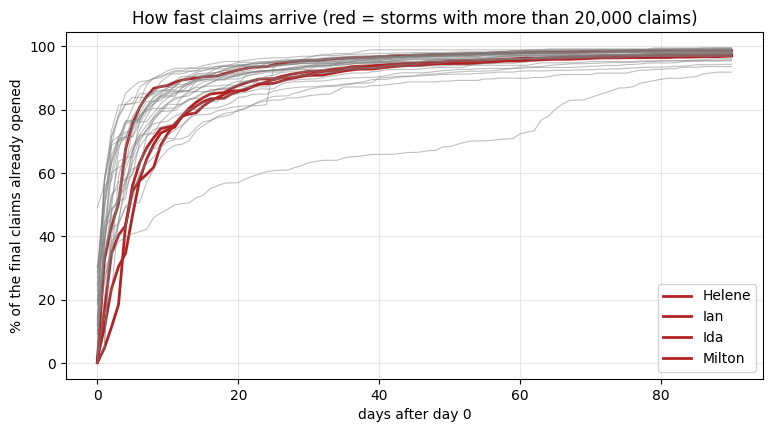

Median share of the final claims opened by day 3 / 7 / 14 / 30:
day 3     56.0
day 7     79.0
day 14    87.0
day 30    94.0


In [2]:
days = np.arange(0, 91)
fig, ax = plt.subplots(figsize=(9, 4.5))
share_rows = []
for name in storms.index:
    s = storm_claims.loc[storm_claims['floodEvent'] == name, 'day']
    share = np.array([(s <= t).mean() for t in days])
    big = storms.loc[name, 'total_claims'] >= 20000
    ax.plot(days, share * 100, color='firebrick' if big else 'gray', lw=2 if big else 0.8, alpha=1 if big else 0.5,
            label=name.replace('Hurricane ', '') if big else None)
    share_rows.append({'storm': name, 'day 3': share[3], 'day 7': share[7], 'day 14': share[14], 'day 30': share[30]})
ax.set_xlabel('days after day 0'); ax.set_ylabel('% of the final claims already opened')
ax.set_title('How fast claims arrive (red = storms with more than 20,000 claims)'); ax.legend(); ax.grid(alpha=0.3)
plt.show()
arrive = pd.DataFrame(share_rows).set_index('storm')
print('Median share of the final claims opened by day 3 / 7 / 14 / 30:')
print((arrive.median() * 100).round(0).to_string())

**What we see.** Claims arrive **fast**. For the median storm, **56%** of all its claims were opened by day 3, **79%** by day 7,
**87%** by day 14 and **94%** by day 30. The big storms (red lines) follow the same kind of curve, so the first week already shows most of the storm.
(1,806 claims were opened before day 0. Day 0 is the most common date of loss, and some storms flooded over several days.)

## 3. First-week claims vs final claims

Each point is one storm. Both axes are on a **log scale**, because storms go from 300 to almost 60,000 claims.

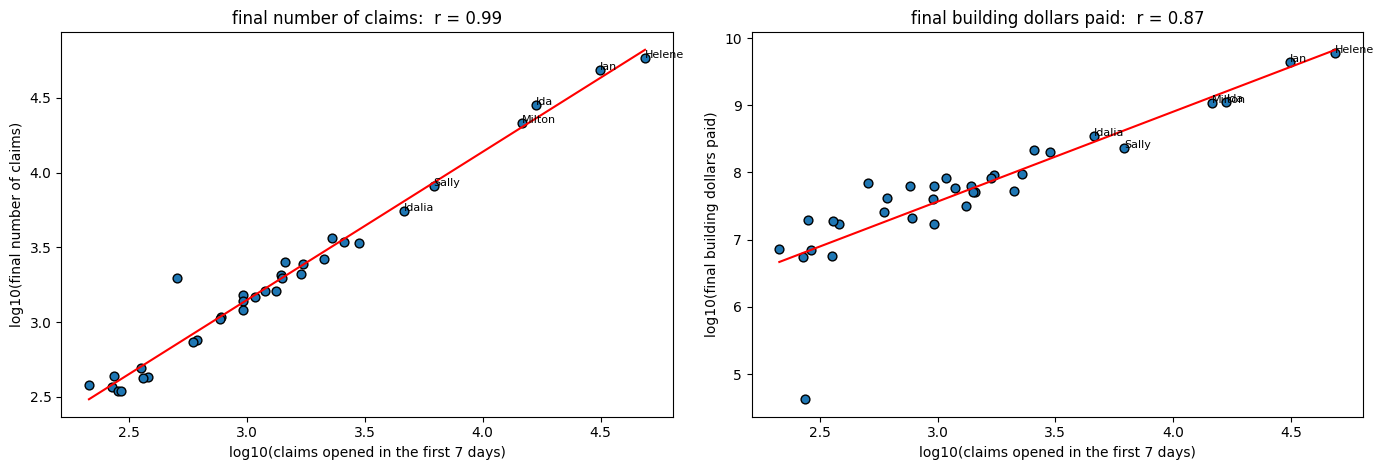

Correlation with log final claims, using claims by day  3: 0.97
Correlation with log final claims, using claims by day  7: 0.99
Correlation with log final claims, using claims by day 14: 0.99
Correlation with log final claims, using claims by day 30: 1.00
Correlation of log claims by day 7 with log final dollars paid: 0.87


In [3]:
x = np.log10(storms['claims_by_day_7'].clip(lower=1))
y_claims = np.log10(storms['total_claims'])
y_paid = np.log10(storms['total_paid'].clip(lower=1))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, yv, title in [(ax[0], y_claims, 'final number of claims'), (ax[1], y_paid, 'final building dollars paid')]:
    a.scatter(x, yv, s=40, edgecolor='black')
    b, c = np.polyfit(x, yv, 1)
    xs = np.linspace(x.min(), x.max(), 50); a.plot(xs, b * xs + c, color='red')
    for name in storms.nlargest(6, 'total_claims').index:
        a.annotate(name.replace('Hurricane ', ''), (x[name], yv[name]), fontsize=8)
    a.set_xlabel('log10(claims opened in the first 7 days)'); a.set_ylabel(f'log10({title})')
    a.set_title(f'{title}:  r = {np.corrcoef(x, yv)[0, 1]:.2f}')
plt.tight_layout(); plt.show()
for n in [3, 7, 14, 30]:
    xn = np.log10(storms[f'claims_by_day_{n}'].clip(lower=1))
    print(f'Correlation with log final claims, using claims by day {n:>2}: {np.corrcoef(xn, y_claims)[0, 1]:.2f}')
print(f'Correlation of log claims by day 7 with log final dollars paid: {np.corrcoef(x, y_paid)[0, 1]:.2f}')

**What we see.** The points lie almost on a straight line. The correlation between the log of claims in the first 7 days and the log of the
final claims is **0.99** (0.97 already with day 3). For the final **dollars** paid the link is weaker (**0.87**), because the dollars also depend
on how bad the damage is, not only on how many claims there are.

## 4. Predicting storms the model has never seen

A correlation uses all storms at once. A fair test is **leave-one-storm-out**: we fit the line on all storms **except one**, predict the
final claims of the left-out storm, and repeat this for every storm. Then we look at how far the predictions are from the truth.

We report the **median error in %** and the share of storms predicted **within a factor of 2** (between half and double the real number).
As a baseline, we predict every storm with the median storm size.

In [4]:
from sklearn.linear_model import LinearRegression

rows, preds = [], {}
for n in [3, 7, 14, 30]:
    xn = np.log10(storms[[f'claims_by_day_{n}']].clip(lower=1))
    p = []
    for name in storms.index:
        train = storms.index != name
        model = LinearRegression().fit(xn[train], y_claims[train])
        p.append(10 ** model.predict(xn[~train])[0])
    p = pd.Series(p, index=storms.index)
    preds[n] = p
    ratio = p / storms['total_claims']
    rows.append({'model': f'claims by day {n}', 'median error %': (np.abs(ratio - 1)).median() * 100,
                 'within a factor of 2': ((ratio >= 0.5) & (ratio <= 2)).mean()})
base = pd.Series([storms['total_claims'].drop(name).median() for name in storms.index], index=storms.index)
ratio = base / storms['total_claims']
rows.append({'model': 'baseline: median storm size', 'median error %': (np.abs(ratio - 1)).median() * 100,
             'within a factor of 2': ((ratio >= 0.5) & (ratio <= 2)).mean()})
loo = pd.DataFrame(rows).set_index('model')
loo.round(2)

,median error %,within a factor of 2
model,,
claims by day 3,23.68,0.94
claims by day 7,13.48,0.97
claims by day 14,8.21,0.97
claims by day 30,5.81,1.00
baseline: median storm size,55.19,0.44


In [5]:
check = pd.DataFrame({'real final claims': storms['total_claims'], 'claims by day 7': storms['claims_by_day_7'],
                      'predicted from day 7': preds[7].round(0)})
check['predicted / real'] = (check['predicted from day 7'] / check['real final claims']).round(2)
check.head(12)

,real final claims,claims by day 7,predicted from day 7,predicted / real
floodEvent,,,,
Hurricane Helene,58018,48850.0,69009.0,1.19
Hurricane Ian,48634,31315.0,41376.0,0.85
Hurricane Ida,28273,16846.0,22387.0,0.79
Hurricane Milton,21594,14672.0,19940.0,0.92
Hurricane Sally,8109,6190.0,8600.0,1.06
Hurricane Idalia,5520,4620.0,6466.0,1.17
Hurricane Eta,3677,2288.0,3182.0,0.87
April Florida Flooding,3440,2580.0,3607.0,1.05
2021 Mid-Spring Severe Storms,3401,2989.0,4201.0,1.24


**What we see**
- With the claims of the **first 7 days**, the median error for a storm the model has never seen is **13%**, and **97%** of the storms are
  predicted within a factor of 2. With day 3 the median error is 24%, with day 14 it is 8%.
- The baseline (always guess the median storm size) has a median error of **55%** and gets only 44% of storms within a factor of 2.
- Examples from day 7: Helene was predicted at 69,009 claims (real 58,018, 1.19 times), Ian at 41,376 (real 48,634, 0.85 times),
  Milton at 19,940 (real 21,594, 0.92 times).

## 5. Early warning: will it be a mega-storm?

In notebook 05 the payment delays started above about **20,000 claims**. Here we turn the prediction into a **yes / no warning**:
"this storm will have more than 20,000 claims". We use the leave-one-storm-out predictions from day 3, 7 and 14, and count how many
mega-storms were warned (recall) and how many warnings were false alarms.

In [6]:
mega = storms['total_claims'] > 20000
print('Mega-storms (over 20,000 claims):', list(storms.index[mega]))
warn_rows = []
for n in [3, 7, 14]:
    warned = preds[n] > 20000
    warn_rows.append({'warning from': f'day {n}', 'mega-storms warned': f'{(warned & mega).sum()} of {mega.sum()}',
                      'false alarms': int((warned & ~mega).sum()), 'storms warned': list(storms.index[warned])})
pd.DataFrame(warn_rows).set_index('warning from')

Mega-storms (over 20,000 claims): ['Hurricane Helene', 'Hurricane Ian', 'Hurricane Ida', 'Hurricane Milton']


,mega-storms warned,false alarms,storms warned
warning from,,,
day 3,2 of 4,0,"[Hurricane Helene, Hurricane Ian]"
day 7,3 of 4,0,"[Hurricane Helene, Hurricane Ian, Hurricane Ida]"
day 14,4 of 4,0,"[Hurricane Helene, Hurricane Ian, Hurricane Id..."


In [7]:
print('Claims opened by day 7 for the biggest storms (and the next ones):')
print(storms[['claims_by_day_3', 'claims_by_day_7', 'total_claims']].head(8).astype(int).to_string())

Claims opened by day 7 for the biggest storms (and the next ones):
                        claims_by_day_3  claims_by_day_7  total_claims
floodEvent                                                            
Hurricane Helene                  29165            48850         58018
Hurricane Ian                     14800            31315         48634
Hurricane Ida                      5226            16846         28273
Hurricane Milton                   8713            14672         21594
Hurricane Sally                    4140             6190          8109
Hurricane Idalia                   3948             4620          5520
Hurricane Eta                      1792             2288          3677
April Florida Flooding             1900             2580          3440


**What we see**
- **By day 3**, the model already warned **2 of the 4** mega-storms (Helene and Ian), with no false alarm.
- **By day 7**, it warned **3 of 4** (also Ida). **Milton** was missed by a little: it was predicted at 19,940 claims, just under the 20,000 line
  (real 21,594).
- **By day 14**, all **4 of 4** mega-storms were warned, still with **no false alarm**.
- The gap between the mega-storms and the rest is big: after one week, the smallest mega-storm (Milton) already had 14,672 claims, while the
  biggest normal storm (Sally) had 6,190.

## 6. Our answer

| Warning time | Median error of the final claims (storm not seen by the model) | Mega-storms warned | False alarms |
|---|---|---|---|
| day 3 | 24% | 2 of 4 | 0 |
| day 7 | 13% | 3 of 4 | 0 |
| day 14 | 8% | 4 of 4 | 0 |
| baseline (median storm) | 55% | - | - |

> **Yes.** About 80% of a storm's claims are opened in the first week, so the first-week count predicts the final number of claims very well
> (correlation 0.99; median error 13% for a storm the model has not seen). It would have warned Helene and Ian after 3 days, Ida after 7 days and
> Milton after 14 days, without a single false alarm. Together with notebook 05 this gives a practical message: the payment delays of the
> mega-storms (about twice as long) could be seen coming in the first one or two weeks, early enough to bring in more adjusters.

**Limits**
- Only 34 storms (2020-2024) and only 4 mega-storms, so the warning results are based on very few cases.
- The final **dollars** are harder to predict (correlation 0.87) than the number of claims, because they also depend on how bad the damage is.
- We use `openDate` from the final file. In real life, claims may reach FEMA's system a few days after they are opened, so a real warning
  would come a little later.